In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, ttest_ind, mannwhitneyu, shapiro, t

df = pd.read_csv("../data/wine_quality_cleaned.csv")
alpha = 0.05
print(df.shape)

(4898, 12)


In [3]:
pearson_r, pearson_p = pearsonr(df["alcohol"], df["quality"])
print("Pearson r      :", round(pearson_r, 4))
print("r squared      :", round(pearson_r ** 2, 4))
print("P-value        :", pearson_p)

Pearson r      : 0.4356
r squared      : 0.1897
P-value        : 5.614770253731286e-226


In [4]:
spearman_r, spearman_p = spearmanr(df["alcohol"], df["quality"])
print("Spearman rho :", round(spearman_r, 4))
print("P-value      :", spearman_p)

Spearman rho : 0.4404
P-value      : 1.6591955335865496e-231


In [ ]:
not_good = df[df["quality"] < 7]["alcohol"]
good = df[df["quality"] >= 7]["alcohol"]

t_stat, t_p = ttest_ind(not_good, good, equal_var=False)

pooled_sd = np.sqrt(((len(not_good) - 1) * not_good.var() + (len(good) - 1) * good.var())
                    / (len(not_good) + len(good) - 2))
cohens_d = (good.mean() - not_good.mean()) / pooled_sd

print("Not Good: n = %d, mean alcohol = %.3f" % (len(not_good), not_good.mean()))
print("Good    : n = %d, mean alcohol = %.3f" % (len(good), good.mean()))
print("Difference in means : %.3f percentage points" % (good.mean() - not_good.mean()))
print("Welch t-statistic   :", round(t_stat, 4))
print("P-value             :", t_p)
print("Cohen's d           :", round(cohens_d, 3))

Not Good: n = 3838, mean alcohol = 10.265
Good    : n = 1060, mean alcohol = 11.416
Difference in means : 1.151 percentage points
Welch t-statistic   : -27.11
P-value             : 1.3020291351134789e-132
Cohen's d           : 1.013


In [6]:
u_stat, u_p = mannwhitneyu(not_good, good, alternative="two-sided")
print("Mann-Whitney U :", u_stat)
print("P-value        :", u_p)

Mann-Whitney U : 1007694.0
P-value        : 4.434501038873333e-140


Shapiro-Wilk W : 0.9509
P-value        : 7.899544155189321e-12


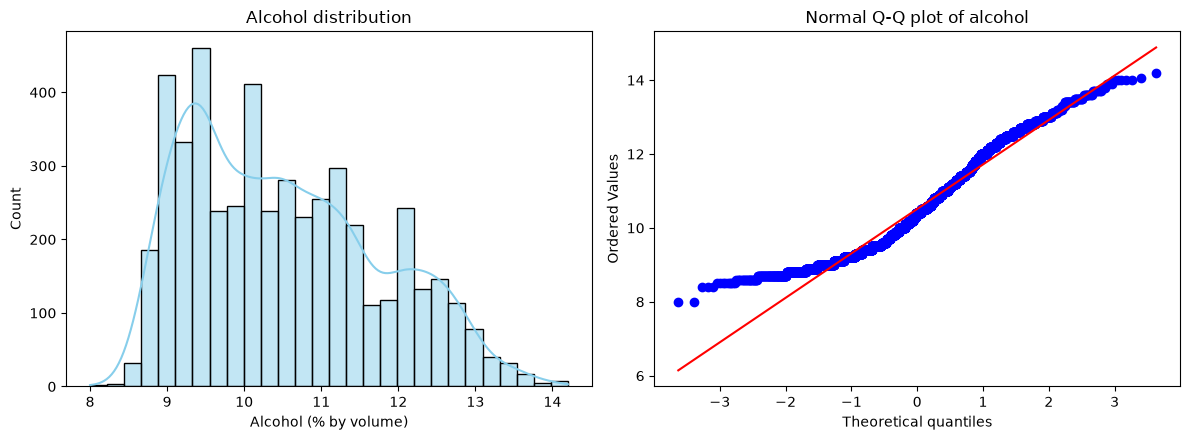

In [7]:
sample = df["alcohol"].sample(n=500, random_state=42)
shapiro_stat, shapiro_p = shapiro(sample)
print("Shapiro-Wilk W :", round(shapiro_stat, 4))
print("P-value        :", shapiro_p)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["alcohol"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Alcohol distribution")
axes[0].set_xlabel("Alcohol (% by volume)")
stats.probplot(df["alcohol"], dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of alcohol")
plt.tight_layout()
plt.savefig("../outputs/charts/alcohol_normality.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
alcohol = df["alcohol"]
n = len(alcohol)
mean = alcohol.mean()
se = alcohol.std(ddof=1) / np.sqrt(n)
margin = t.ppf(0.975, n - 1) * se

ci_lower, ci_upper = mean - margin, mean + margin
print("Sample size     :", n)
print("Mean alcohol    : %.4f" % mean)
print("95%% CI for mean : %.4f to %.4f" % (ci_lower, ci_upper))

Sample size     : 4898
Mean alcohol    : 10.5143
95% CI for mean : 10.4798 to 10.5487


In [10]:
def decide(p):
    return "Reject H0" if p < alpha else "Fail to reject H0"

results = pd.DataFrame({
    "Test": ["Pearson correlation", "Spearman correlation", "Welch t-test", "Mann-Whitney U", "Shapiro-Wilk"],
    "H0": [
        "No linear relationship between alcohol and quality",
        "No monotonic relationship between alcohol and quality",
        "Mean alcohol is equal in Good and Not Good wines",
        "Alcohol has the same distribution in Good and Not Good wines",
        "Alcohol is normally distributed",
    ],
    "H1": [
        "A linear relationship exists",
        "A monotonic relationship exists",
        "Mean alcohol differs between the groups",
        "The distributions differ",
        "Alcohol is not normally distributed",
    ],
    "Significance Level": [alpha] * 5,
    "Test Statistic": [pearson_r, spearman_r, t_stat, u_stat, shapiro_stat],
    "P-value": [pearson_p, spearman_p, t_p, u_p, shapiro_p],
})
results["Decision"] = results["P-value"].apply(decide)
results["Conclusion"] = [
    "Moderate positive linear relationship (r = %.2f): higher alcohol goes with higher quality." % pearson_r,
    "Moderate positive monotonic relationship (rho = %.2f); confirms the Pearson result." % spearman_r,
    "Good wines have clearly higher mean alcohol (%.2f vs %.2f); Cohen's d = %.2f (large effect)." % (good.mean(), not_good.mean(), cohens_d),
    "Distributions differ significantly; confirms the t-test without assuming normality.",
    "Alcohol is not normally distributed, so rank-based tests (Spearman, Mann-Whitney) are a sensible check.",
]

shown = results.round(4)
shown["P-value"] = results["P-value"].map("{:.3g}".format)   # show tiny p-values in scientific form
display(shown)



,Test,H0,H1,Significance Level,Test Statistic,P-value,Decision,Conclusion
0,Pearson correlation,No linear relationship between alcohol and qua...,A linear relationship exists,0.05,4.356000e-01,5.61e-226,Reject H0,Moderate positive linear relationship (r = 0.4...
1,Spearman correlation,No monotonic relationship between alcohol and ...,A monotonic relationship exists,0.05,4.404000e-01,1.66e-231,Reject H0,Moderate positive monotonic relationship (rho ...
2,Welch t-test,Mean alcohol is equal in Good and Not Good wines,Mean alcohol differs between the groups,0.05,-2.711000e+01,1.3e-132,Reject H0,Good wines have clearly higher mean alcohol (1...
3,Mann-Whitney U,Alcohol has the same distribution in Good and ...,The distributions differ,0.05,1.007694e+06,4.43e-140,Reject H0,Distributions differ significantly; confirms t...
4,Shapiro-Wilk,Alcohol is normally distributed,Alcohol is not normally distributed,0.05,9.509000e-01,7.9e-12,Reject H0,"Alcohol is not normally distributed, so rank-b..."



1. Pearson correlation.r = 0.463 with a p-value of about 1.4e-209, far below 0.05, so we reject H0. Alcohol and quality have a moderate positive linear relationship. r squared = 0.214, so alcohol alone accounts for roughly 21% of the variation in quality.

2. Spearman correlation.rho = 0.476 (p about 7.1e-223): we reject H0. The relationship holds when only the ranks are used, so it is not driven by a few extreme values and does not rely on a linear shape.

3. Welch's t-test.Wines scored 7 or above have a mean alcohol of 11.58% versus 10.33% for the others, a difference of about 1.25 percentage points (t = -28.16, p about 1.3e-135). We reject H0. Cohen's d = 1.13, which is a largeeff ect.

4. Mann-Whitney U U = 560,713.5, p about 7.3e-139: we reject H0, agreeing with the t-test without assuming normality.

5. Normality (Shapiro-Wilk)  W = 0.9645, p about 1.2e-9: we reject H0, so alcohol is not normally distributed (it is right-skewed with several peaks). This is why the Spearman and Mann-Whitney checks were included. With a large sample the t-test and Pearson test are still reasonably reliable (central limit theorem), and the non-parametric tests agree with them.

6. Confidence interval The mean alcohol content is estimated at 10.589%, with a 95% confidence interval of 10.551% to 10.627%. The interval is narrow because the sample is large (n = 3,961).

Statistical vs practical significance
Statistical significance only says that the result is unlikely under H0. With about 4,000 wines, even tiny effects give very small p-values, so the p-values here (all far below 0.05) should not be read as "strength".
Practical significance is judged from effect sizes: r = 0.46 (moderate), Cohen's d = 1.13 (large), and a gap of about 1.25 percentage points of alcohol between Good and Not Good wines. These are meaningful for a winemaker.
But r squared = 0.21 means 79% of the variation in quality is not explained by alcohol, so alcohol alone is not enough to predict quality.
These tests show association, not causation: other variables (density, sugar, chlorides) are related to alcohol and may contribute.